In [1]:
from pathlib import Path

# Change this path to your actual dataset location
dataset_path = Path("../data/skin_dataset_clean")

for folder in ["train", "test", "valid"]:
    folder_path = dataset_path / folder

    print(f"\n{folder.upper()}")

    if folder_path.exists():
        for class_folder in folder_path.iterdir():
            if class_folder.is_dir():
                image_count = sum(
                    1 for file in class_folder.iterdir()
                    if file.is_file()
                )
                print(class_folder.name, ":", image_count, "files")
    else:
        print("Folder not found:", folder_path.resolve())



TRAIN
acne : 207 files
dry : 198 files
oil : 198 files

TEST
acne : 10 files
dry : 9 files
oil : 9 files

VALID
acne : 20 files
dry : 19 files
oil : 19 files


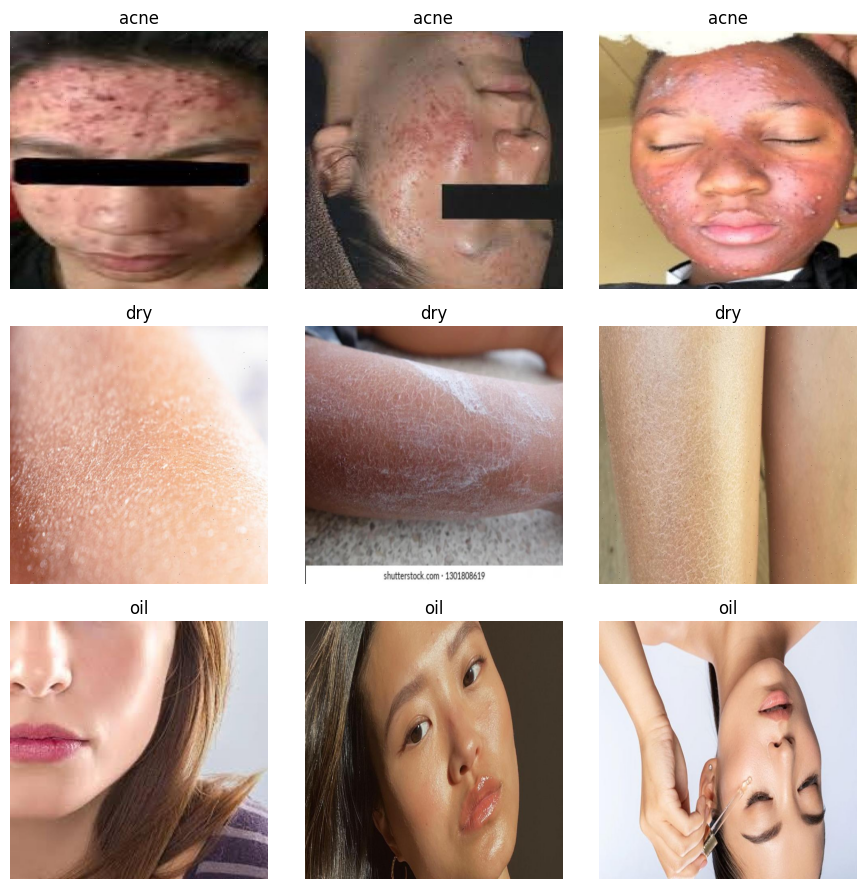

In [2]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

dataset_path = Path("../data/skin_dataset_clean")
train_path = dataset_path / "train"

classes = ["acne", "dry", "oil"]

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for row, class_name in enumerate(classes):
    class_path = train_path / class_name

    # Get image files
    image_files = [
        p for p in class_path.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
    ]

    # Select up to 3 random images
    samples = random.sample(image_files, min(3, len(image_files)))

    for col, image_path in enumerate(samples):
        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("RGB"))

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [3]:
from pathlib import Path

dataset_path = Path("../data/skin_dataset_clean")
image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")

    for class_name in ["acne", "dry", "oil"]:
        class_path = dataset_path / split / class_name

        images = [
            file for file in class_path.iterdir()
            if file.is_file()
            and file.suffix.lower() in image_extensions
        ]

        print(f"{class_name}: {len(images)} images")



TRAIN
acne: 207 images
dry: 198 images
oil: 198 images

VALID
acne: 20 images
dry: 19 images
oil: 19 images

TEST
acne: 10 images
dry: 9 images
oil: 9 images


In [3]:
import torch
import torchvision.models as models
from torchvision.models import ResNet18_Weights

device = torch.device("cpu")

weights = ResNet18_Weights.DEFAULT
feature_extractor = models.resnet18(weights=weights)

# Remove the final classification layer
feature_extractor.fc = torch.nn.Identity()

feature_extractor = feature_extractor.to(device)
feature_extractor.eval()

preprocess = weights.transforms()

print("Feature extractor loaded successfully!")
print("Device:", device)

Feature extractor loaded successfully!
Device: cpu


In [5]:
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import numpy as np

dataset_path = Path("../data/skin_dataset_clean")
classes = ["acne", "dry", "oil"]
class_to_idx = {name: i for i, name in enumerate(classes)}

image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

class SkinDataset(Dataset):
    def __init__(self, split):
        self.samples = []

        for class_name in classes:
            folder = dataset_path / split / class_name

            for path in folder.iterdir():
                if path.is_file() and path.suffix.lower() in image_extensions:
                    self.samples.append(
                        (path, class_to_idx[class_name])
                    )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]

        with Image.open(path) as img:
            image = preprocess(img.convert("RGB"))

        return image, label

def extract_features(split):
    dataset = SkinDataset(split)
    loader = DataLoader(dataset, batch_size=16, shuffle=False)

    features = []
    labels = []

    with torch.no_grad():
        for images, targets in loader:
            outputs = feature_extractor(images.to(device))
            features.append(outputs.cpu().numpy())
            labels.append(targets.numpy())

    return np.concatenate(features), np.concatenate(labels)

X_train, y_train = extract_features("train")
X_valid, y_valid = extract_features("valid")
X_test, y_test = extract_features("test")

print("Training features:", X_train.shape)
print("Validation features:", X_valid.shape)
print("Testing features:", X_test.shape)

Training features: (603, 512)
Validation features: (58, 512)
Testing features: (28, 512)


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train, y_train)

valid_predictions = lr_model.predict(X_valid)

print("Validation accuracy:",
      accuracy_score(y_valid, valid_predictions))

print("\nValidation classification report:")
print(classification_report(
    y_valid,
    valid_predictions,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

Validation accuracy: 0.8793103448275862

Validation classification report:
              precision    recall  f1-score   support

        acne       0.83      0.95      0.88        20
         dry       0.89      0.89      0.89        19
         oil       0.94      0.79      0.86        19

    accuracy                           0.88        58
   macro avg       0.89      0.88      0.88        58
weighted avg       0.89      0.88      0.88        58



In [7]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

test_predictions = lr_model.predict(X_test)

print("Test accuracy:",
      accuracy_score(y_test, test_predictions))

print("\nTest classification report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, test_predictions))


Test accuracy: 0.9642857142857143

Test classification report:
              precision    recall  f1-score   support

        acne       0.91      1.00      0.95        10
         dry       1.00      0.89      0.94         9
         oil       1.00      1.00      1.00         9

    accuracy                           0.96        28
   macro avg       0.97      0.96      0.96        28
weighted avg       0.97      0.96      0.96        28


Confusion matrix:
[[10  0  0]
 [ 1  8  0]
 [ 0  0  9]]


In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Evaluate on validation data
rf_valid_predictions = rf_model.predict(X_valid)

print("Random Forest validation accuracy:",
      accuracy_score(y_valid, rf_valid_predictions))

print("\nValidation classification report:")
print(classification_report(
    y_valid,
    rf_valid_predictions,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))


Random Forest validation accuracy: 0.8103448275862069

Validation classification report:
              precision    recall  f1-score   support

        acne       0.77      0.85      0.81        20
         dry       0.83      0.79      0.81        19
         oil       0.83      0.79      0.81        19

    accuracy                           0.81        58
   macro avg       0.81      0.81      0.81        58
weighted avg       0.81      0.81      0.81        58



In [9]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf_test_predictions = rf_model.predict(X_test)

print("Random Forest test accuracy:",
      accuracy_score(y_test, rf_test_predictions))

print("\nTest classification report:")
print(classification_report(
    y_test,
    rf_test_predictions,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, rf_test_predictions))


Random Forest test accuracy: 0.8928571428571429

Test classification report:
              precision    recall  f1-score   support

        acne       0.82      0.90      0.86        10
         dry       1.00      0.78      0.88         9
         oil       0.90      1.00      0.95         9

    accuracy                           0.89        28
   macro avg       0.91      0.89      0.89        28
weighted avg       0.90      0.89      0.89        28


Confusion matrix:
[[9 0 1]
 [2 7 0]
 [0 0 9]]


In [10]:

from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, class_weight="balanced")
)

# Train SVM
svm_model.fit(X_train, y_train)

# Evaluate on validation data
svm_valid_predictions = svm_model.predict(X_valid)

print("SVM validation accuracy:",
      accuracy_score(y_valid, svm_valid_predictions))

print("\nValidation classification report:")
print(classification_report(
    y_valid,
    svm_valid_predictions,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))


SVM validation accuracy: 0.8793103448275862

Validation classification report:
              precision    recall  f1-score   support

        acne       0.83      1.00      0.91        20
         dry       0.89      0.84      0.86        19
         oil       0.94      0.79      0.86        19

    accuracy                           0.88        58
   macro avg       0.89      0.88      0.88        58
weighted avg       0.89      0.88      0.88        58



In [11]:

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

svm_test_predictions = svm_model.predict(X_test)

print("SVM test accuracy:",
      accuracy_score(y_test, svm_test_predictions))

print("\nTest classification report:")
print(classification_report(
    y_test,
    svm_test_predictions,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, svm_test_predictions))


SVM test accuracy: 0.9285714285714286

Test classification report:
              precision    recall  f1-score   support

        acne       0.83      1.00      0.91        10
         dry       1.00      0.78      0.88         9
         oil       1.00      1.00      1.00         9

    accuracy                           0.93        28
   macro avg       0.94      0.93      0.93        28
weighted avg       0.94      0.93      0.93        28


Confusion matrix:
[[10  0  0]
 [ 2  7  0]
 [ 0  0  9]]


In [12]:

from pathlib import Path
from collections import defaultdict
import hashlib

dataset_path = Path("../data/skin_dataset_clean")
splits = ["train", "valid", "test"]
classes = ["acne", "dry", "oil"]

image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

hash_groups = defaultdict(list)

for split in splits:
    for class_name in classes:
        folder = dataset_path / split / class_name

        for path in folder.iterdir():
            if path.is_file() and path.suffix.lower() in image_extensions:
                with open(path, "rb") as f:
                    file_hash = hashlib.sha256(f.read()).hexdigest()

                hash_groups[file_hash].append(
                    (split, class_name, str(path))
                )

duplicates = {
    h: files for h, files in hash_groups.items()
    if len(files) > 1
}

print("Total image files:", sum(len(v) for v in hash_groups.values()))
print("Exact duplicate groups:", len(duplicates))

for group_number, files in enumerate(duplicates.values(), start=1):
    print(f"\nDuplicate group {group_number}:")
    for split, class_name, path in files:
        print(f"  Split: {split} | Class: {class_name} | File: {path}")


Total image files: 689
Exact duplicate groups: 0


In [13]:

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from pathlib import Path

clean_path = Path("../data/skin_dataset_clean")

device = torch.device("cpu")

transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    clean_path / "train",
    transform=transform
)

valid_dataset = datasets.ImageFolder(
    clean_path / "valid",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    clean_path / "test",
    transform=transform
)

train_loader = DataLoader(
    train_dataset, batch_size=16, shuffle=True
)

valid_loader = DataLoader(
    valid_dataset, batch_size=16, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=16, shuffle=False
)

print("Classes:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(valid_dataset))
print("Test images:", len(test_dataset))
print("Device:", device)


Classes: ['acne', 'dry', 'oil']
Training images: 603
Validation images: 58
Test images: 28
Device: cpu


In [14]:
import torch
from torch import nn

class SkinCNN(nn.Module):
    def __init__(self, num_classes=3):
        super().__init__()

        self.features = nn.Sequential(
            # Convolution block 1
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolution block 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Convolution block 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = SkinCNN(num_classes=3).to(device)

print(model)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

SkinCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=32, out_features=3, bias=True)
  )
)
Total parameters: 25763


In [15]:
import copy

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 15

best_valid_accuracy = 0.0
best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(epochs):
    # Training
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # Validation
    model.eval()
    valid_correct = 0
    valid_total = 0

    with torch.no_grad():
        for images, labels in valid_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            valid_correct += (predictions == labels).sum().item()
            valid_total += labels.size(0)

    valid_accuracy = valid_correct / valid_total

    # Save the best model based on validation accuracy
    if valid_accuracy > best_valid_accuracy:
        best_valid_accuracy = valid_accuracy
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch + 1:02d}/{epochs} | "
        f"Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2%} | "
        f"Validation Accuracy: {valid_accuracy:.2%}"
    )

model.load_state_dict(best_model_state)

print("\nBest validation accuracy:", f"{best_valid_accuracy:.2%}")

Epoch 01/15 | Loss: 1.1015 | Train Accuracy: 33.33% | Validation Accuracy: 46.55%
Epoch 02/15 | Loss: 1.0778 | Train Accuracy: 40.30% | Validation Accuracy: 41.38%
Epoch 03/15 | Loss: 1.0630 | Train Accuracy: 40.63% | Validation Accuracy: 51.72%
Epoch 04/15 | Loss: 1.0180 | Train Accuracy: 48.76% | Validation Accuracy: 58.62%
Epoch 05/15 | Loss: 0.9635 | Train Accuracy: 51.58% | Validation Accuracy: 55.17%
Epoch 06/15 | Loss: 0.9401 | Train Accuracy: 54.89% | Validation Accuracy: 53.45%
Epoch 07/15 | Loss: 0.8800 | Train Accuracy: 60.70% | Validation Accuracy: 56.90%
Epoch 08/15 | Loss: 0.8772 | Train Accuracy: 59.54% | Validation Accuracy: 56.90%
Epoch 09/15 | Loss: 0.8216 | Train Accuracy: 63.68% | Validation Accuracy: 56.90%
Epoch 10/15 | Loss: 0.8024 | Train Accuracy: 67.66% | Validation Accuracy: 55.17%
Epoch 11/15 | Loss: 0.7497 | Train Accuracy: 71.31% | Validation Accuracy: 60.34%
Epoch 12/15 | Loss: 0.7470 | Train Accuracy: 70.15% | Validation Accuracy: 62.07%
Epoch 13/15 | Lo

In [17]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model.eval()

y_true_cnn = []
y_pred_cnn = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true_cnn.extend(labels.numpy())
        y_pred_cnn.extend(predictions.cpu().numpy())

cnn_test_accuracy = accuracy_score(y_true_cnn, y_pred_cnn)

print(f"CNN Test Accuracy: {cnn_test_accuracy:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_true_cnn,
        y_pred_cnn,
        labels=[0, 1, 2],
        target_names=train_dataset.classes,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true_cnn, y_pred_cnn))

CNN Test Accuracy: 71.43%

Classification Report:
              precision    recall  f1-score   support

        acne       0.67      0.60      0.63        10
         dry       0.83      0.56      0.67         9
         oil       0.69      1.00      0.82         9

    accuracy                           0.71        28
   macro avg       0.73      0.72      0.71        28
weighted avg       0.73      0.71      0.70        28


Confusion Matrix:
[[6 1 3]
 [3 5 1]
 [0 0 9]]


In [19]:
import joblib
from pathlib import Path

Path("../models").mkdir(parents=True, exist_ok=True)

joblib.dump(lr_model, "../models/skin_model.joblib")

['../models/skin_model.joblib']